# import libraries

In [31]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)

In [32]:
df= pd.read_csv("network_flow.csv")


In [33]:
df.head(3)

,flow_duration_ms,protocol,destination_port,total_fwd_packets,total_bwd_packets,total_fwd_bytes,total_bwd_bytes,packets_per_second,bytes_per_second,syn_flag_count,ack_flag_count,rst_flag_count,unique_dst_ports_1min,failed_login_attempts_1min,label
0,441.14,TCP,443,7,11,5691,7654,40.80,30251.38,0,10,1,8,0,BENIGN
1,2753.46,TCP,22,26,21,1799,5203,17.07,2542.98,4,12,0,3,7,BruteForce
2,2960.39,TCP,443,9,9,5899,5779,6.08,3944.75,0,6,0,5,0,BENIGN


In [34]:
df.isnull().sum()

flow_duration_ms              0
protocol                      0
destination_port              0
total_fwd_packets             0
total_bwd_packets             0
total_fwd_bytes               0
total_bwd_bytes               0
packets_per_second            0
bytes_per_second              0
syn_flag_count                0
ack_flag_count                0
rst_flag_count                0
unique_dst_ports_1min         0
failed_login_attempts_1min    0
label                         0
dtype: int64

In [35]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
11995    False
11996    False
11997    False
11998    False
11999    False
Length: 12000, dtype: bool

In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   flow_duration_ms            12000 non-null  float64
 1   protocol                    12000 non-null  str    
 2   destination_port            12000 non-null  int64  
 3   total_fwd_packets           12000 non-null  int64  
 4   total_bwd_packets           12000 non-null  int64  
 5   total_fwd_bytes             12000 non-null  int64  
 6   total_bwd_bytes             12000 non-null  int64  
 7   packets_per_second          12000 non-null  float64
 8   bytes_per_second            12000 non-null  float64
 9   syn_flag_count              12000 non-null  int64  
 10  ack_flag_count              12000 non-null  int64  
 11  rst_flag_count              12000 non-null  int64  
 12  unique_dst_ports_1min       12000 non-null  int64  
 13  failed_login_attempts_1min  12000 non-null

In [37]:
df.describe()

,flow_duration_ms,destination_port,total_fwd_packets,total_bwd_packets,total_fwd_bytes,total_bwd_bytes,packets_per_second,bytes_per_second,syn_flag_count,ack_flag_count,rst_flag_count,unique_dst_ports_1min,failed_login_attempts_1min
count,12000.000000,12000.000000,12000.000000,12000.000000,1.200000e+04,12000.000000,12000.000000,1.200000e+04,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000
mean,2192.755723,6232.002917,67.752250,23.391750,2.043051e+04,12040.979167,323.095854,9.291211e+04,25.077000,12.752167,0.827917,31.230583,2.807667
std,3574.794305,14219.386564,169.923039,28.817894,5.000175e+04,20692.075181,1439.426978,4.200523e+05,94.570774,19.712947,1.222809,75.745295,8.043521
min,9.430000,13.000000,1.000000,0.000000,1.110000e+02,0.000000,0.190000,3.214000e+01,0.000000,0.000000,0.000000,1.000000,0.000000
25%,273.330000,53.000000,12.000000,6.000000,2.252250e+03,1195.000000,15.187500,3.995913e+03,0.000000,0.000000,0.000000,3.000000,0.000000
50%,861.115000,443.000000,22.000000,15.000000,7.404000e+03,4899.000000,48.510000,1.396520e+04,3.000000,6.000000,0.000000,4.000000,0.000000
75%,2598.437500,3389.000000,48.000000,30.000000,2.021950e+04,14138.500000,167.777500,5.413706e+04,7.000000,17.000000,1.000000,6.000000,1.000000
max,71760.910000,65534.000000,7518.000000,552.000000,2.805062e+06,374998.000000,72807.410000,2.599478e+07,2574.000000,363.000000,8.000000,1202.000000,172.000000


In [38]:
df["label"].value_counts()

label
BENIGN        6000
BruteForce    2000
DDoS          2000
PortScan      2000
Name: count, dtype: int64

# Step 2: Separate inputs and outputs

In [39]:
X = df.drop(columns=["label"])
y = df["label"]

# Convert categorical inputs into numbers

In [40]:
X = pd.get_dummies(X)

# Convert target labels into numbers

In [46]:
encoder = LabelEncoder()
y = encoder.fit_transform(df['label'].astype(str))

# Step 3: Split data

In [47]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

In [49]:
numeric = X.select_dtypes(include=np.number).columns.tolist()
categorical = X.select_dtypes(exclude=np.number).columns.tolist()

# Convert boolean columns to integers
bool_cols = X.select_dtypes(include="bool").columns.tolist()

for df in [X_train, X_val, X_test]:
    df[bool_cols] = df[bool_cols].astype(int)

numeric = numeric + bool_cols
categorical = [col for col in categorical if col not in bool_cols]

preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('fill', SimpleImputer(strategy='median')),
        ('scale', StandardScaler())
    ]), numeric),

    ('cat', Pipeline([
        ('fill', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(handle_unknown='ignore',
                                 sparse_output=False))
    ]), categorical)
])

X_train = preprocessor.fit_transform(X_train).astype('float32')
X_val = preprocessor.transform(X_val).astype('float32')
X_test = preprocessor.transform(X_test).astype('float32')

# Step 4: Choose different models

In [50]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'Decision Tree': DecisionTreeClassifier(random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=100, eval_metric='mlogloss',
                             random_state=SEED, n_jobs=2)
}
trained = {}
validation_scores = {}
for name, model in models.items():
    print('Training', name)
    model.fit(X_train, y_train)
    trained[name] = model
    pred = model.predict(X_val)
    validation_scores[name] = precision_recall_fscore_support(
        y_val, pred, average='macro', zero_division=0)[2]

Training Logistic Regression
Training Decision Tree
Training Random Forest
Training XGBoost


In [51]:
class IntrusionANN(nn.Module):
    def __init__(self, input_size, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        return self.network(x)

ann = IntrusionANN(X_train.shape[1], len(encoder.classes_))
optimizer = torch.optim.Adam(ann.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()
loader = DataLoader(TensorDataset(torch.from_numpy(X_train),
                                  torch.from_numpy(y_train).long()),
                    batch_size=128, shuffle=True)
loss_history = []
for epoch in range(15):
    ann.train()
    total_loss = 0.0
    for xb, yb in loader:
        optimizer.zero_grad()
        loss = loss_fn(ann(xb), yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(xb)
    average_loss = total_loss / len(X_train)
    loss_history.append(average_loss)
    print(f'ANN epoch {epoch+1:02d}: loss={average_loss:.4f}')

ann.eval()
def ann_predict(values):
    with torch.no_grad():
        return ann(torch.from_numpy(values)).argmax(dim=1).numpy()

validation_scores['ANN'] = precision_recall_fscore_support(
    y_val, ann_predict(X_val), average='macro', zero_division=0)[2]
print('\nValidation macro-F1:', validation_scores)
best_name = max(validation_scores, key=validation_scores.get)
print('Selected model:', best_name)

ANN epoch 01: loss=0.6771
ANN epoch 02: loss=0.0417
ANN epoch 03: loss=0.0177
ANN epoch 04: loss=0.0119
ANN epoch 05: loss=0.0101
ANN epoch 06: loss=0.0075
ANN epoch 07: loss=0.0058
ANN epoch 08: loss=0.0057
ANN epoch 09: loss=0.0051
ANN epoch 10: loss=0.0043
ANN epoch 11: loss=0.0049
ANN epoch 12: loss=0.0047
ANN epoch 13: loss=0.0041
ANN epoch 14: loss=0.0026
ANN epoch 15: loss=0.0031

Validation macro-F1: {'Logistic Regression': 0.9966648044969233, 'Decision Tree': 0.9944470201760468, 'Random Forest': 0.9988878059807411, 'XGBoost': 0.9994450605300227, 'ANN': 0.9977734354722689}
Selected model: XGBoost


#5. Test comparison (test data were never used for fitting or model selection).

In [54]:
rows = []
test_predictions = {}
for name in list(models) + ['ANN']:
    pred = ann_predict(X_test) if name == 'ANN' else trained[name].predict(X_test)
    test_predictions[name] = pred
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, pred, average='macro', zero_division=0)
    rows.append({'Model': name, 'Accuracy': accuracy_score(y_test, pred),
                 'Precision': precision, 'Recall': recall, 'F1-score': f1})
results = pd.DataFrame(rows)
print('\nTEST SET RESULTS:\n', results.round(4).to_string(index=False))
results.to_csv( 'model_comparison.csv', index=False)
print('\nBest model classification report:\n', classification_report(
    y_test, test_predictions[best_name], target_names=encoder.classes_, zero_division=0))



TEST SET RESULTS:
               Model  Accuracy  Precision  Recall  F1-score
Logistic Regression    0.9961     0.9975  0.9947    0.9961
      Decision Tree    0.9950     0.9942  0.9953    0.9947
      Random Forest    0.9983     0.9986  0.9975    0.9981
            XGBoost    0.9983     0.9986  0.9981    0.9983
                ANN    0.9978     0.9983  0.9967    0.9975

Best model classification report:
               precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00       900
  BruteForce       1.00      1.00      1.00       300
        DDoS       1.00      1.00      1.00       300
    PortScan       1.00      1.00      1.00       300

    accuracy                           1.00      1800
   macro avg       1.00      1.00      1.00      1800
weighted avg       1.00      1.00      1.00      1800



6. Graph A: Accuracy by model

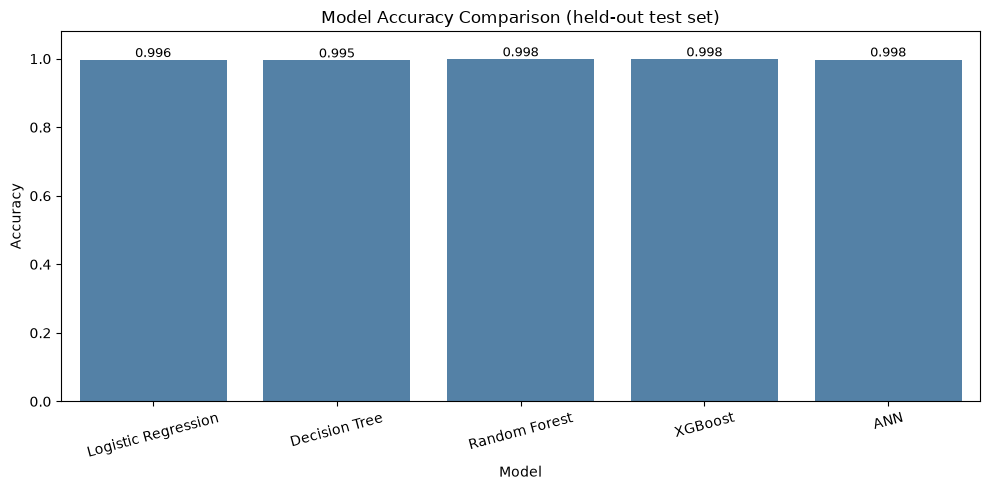

In [61]:
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=results, x='Model', y='Accuracy', color='steelblue')
for bar in ax.patches:
    ax.annotate(f'{bar.get_height():.3f}',
                (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.ylim(0, 1.08)
plt.xticks(rotation=15)
plt.title('Model Accuracy Comparison (held-out test set)')
plt.tight_layout()
plt.savefig('model_accuracy.png', dpi=300)
plt.show()

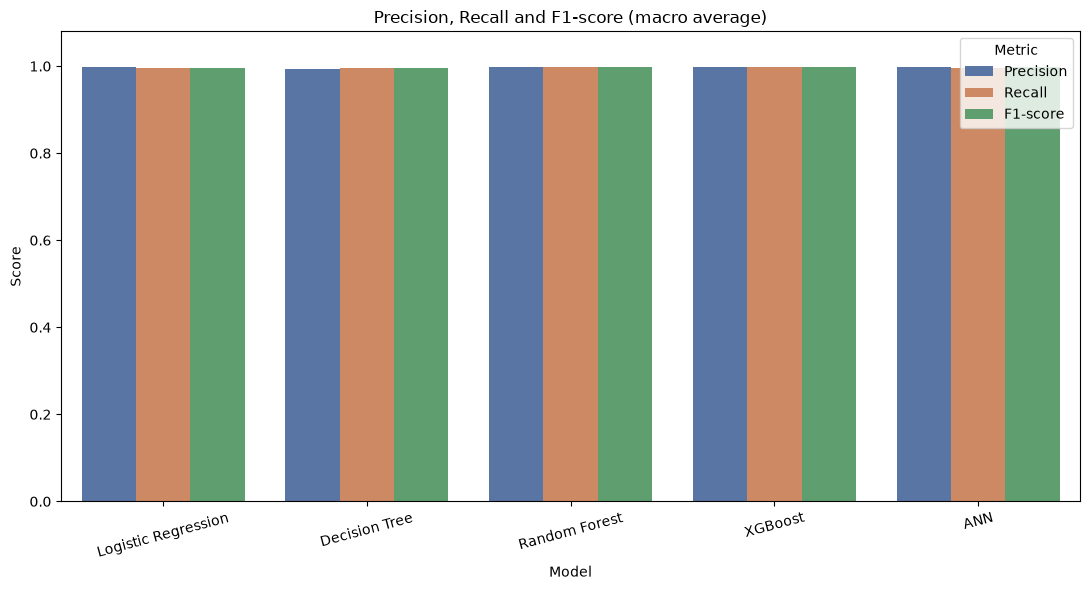

In [60]:
long = results.melt(id_vars='Model', value_vars=['Precision', 'Recall', 'F1-score'],
                    var_name='Metric', value_name='Score')
plt.figure(figsize=(11, 6))
sns.barplot(data=long, x='Model', y='Score', hue='Metric', palette='deep')
plt.ylim(0, 1.08)
plt.xticks(rotation=15)
plt.title('Precision, Recall and F1-score (macro average)')
plt.tight_layout()
plt.savefig('model_metrics.png', dpi=300)
plt.show()

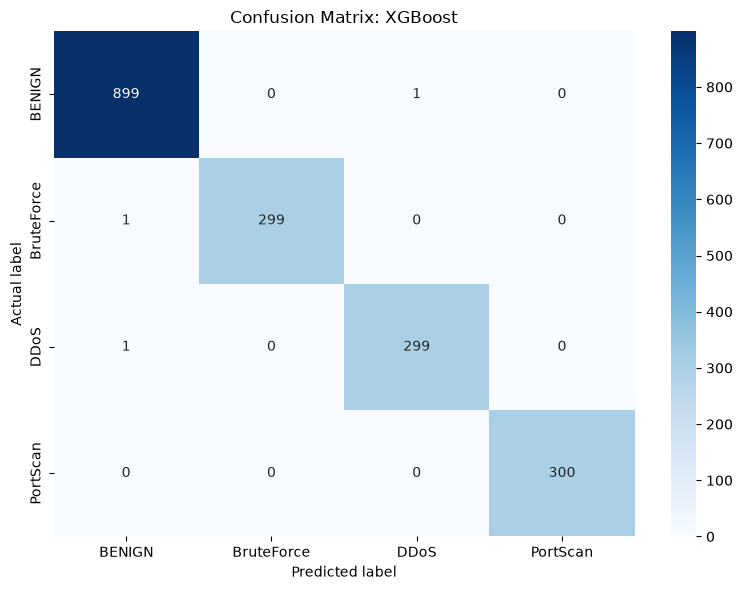

In [59]:
cm = confusion_matrix(y_test, test_predictions[best_name],
                      labels=np.arange(len(encoder.classes_)))
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=encoder.classes_, yticklabels=encoder.classes_)
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.title(f'Confusion Matrix: {best_name}')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300)
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(loss_history) + 1), loss_history, marker='o')
plt.xlabel('Epoch')
plt.ylabel('Cross-entropy loss')
plt.title('ANN Training Loss')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('ann_loss.png', dpi=300)
plt.close()
print('\nSaved four graphs and model_comparison.csv to:', Path('.').resolve())